In [1]:
%load_ext autoreload
%autoreload 2

import open3d as o3d
import numpy as np
import os
import sys
from glob import glob
import pickle
import scipy
import pandas as pd

import sys
sys.path.append('D:\Dev\Point-Cloud-Registration\source')
from utils.write_output import write_array2txt

from cylinder_extraction.cylinder import Cylinder
from cylinder_extraction.station import Station
from registration.utils import multiway_load_point_clouds as load_point_clouds
from registration.utils import multiway_full_registration as full_registration
from registration.utils import pairwise_registration, combine_point_cloud, multiway_filter_point_clouds

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
def find_ground_z(pcd):
    points = np.asanyarray(pcd.points)
    z_max = points[:,2].max()
    step = 0.1
    cnt = []
    for z in np.arange(0, z_max, step):
        if z % 10 == 0:
            print(z)
        ind = (z <= points[:,2]) & (points[:,2] < z + step)
        cnt.append(ind.sum())
    cnt = np.array(cnt)
    diff = np.diff(cnt)
    diff = np.insert(diff, 0, cnt[0])
    # find the left most peak among the top 5 peaks
    peak_indices = scipy.signal.find_peaks(diff)
    peak_indices = peak_indices[0]

    z = peak_indices[np.argsort(diff[peak_indices])[-5:]].min()

    return z * step

In [3]:
data_dir = 'D:/REGISTRATION DATA/External/JB-505 100ft EXT Trimble/tank_8/ext_ground'

In [4]:
files = glob(os.path.join(data_dir, '*.txt'))
for f in files:
    fn = os.path.split(f)[-1]
    fn = fn.split('.')[0]
    try:
        int(fn)
    except Exception:
        continue
    print(f)
    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(
        pd.read_csv(f, delimiter=" ").values
    )
    z_base = find_ground_z(pcd)
    points = np.asarray(pcd.points)
    # points[:,2] -= z_base
    pcd.translate((0,0,-z_base))
    # save
    o3d.io.write_point_cloud(
        os.path.join(data_dir, f'{fn}.pcd'),
        pcd, print_progress=True
    )


D:/REGISTRATION DATA/External/JB-505 100ft EXT Trimble/tank_8/ext_ground\009.txt
0.0
10.0
20.0
30.0
40.0
50.0
60.0
70.0
80.0
90.0
100.0
110.0
D:/REGISTRATION DATA/External/JB-505 100ft EXT Trimble/tank_8/ext_ground\010.txt
0.0
10.0
20.0
D:/REGISTRATION DATA/External/JB-505 100ft EXT Trimble/tank_8/ext_ground\011.txt
0.0
10.0
20.0
30.0
40.0
50.0
60.0
70.0
80.0
90.0
100.0
110.0
120.0
D:/REGISTRATION DATA/External/JB-505 100ft EXT Trimble/tank_8/ext_ground\012.txt
0.0
10.0
20.0
30.0
40.0
50.0
60.0
70.0
80.0
D:/REGISTRATION DATA/External/JB-505 100ft EXT Trimble/tank_8/ext_ground\013.txt
0.0
10.0
20.0
30.0
40.0
D:/REGISTRATION DATA/External/JB-505 100ft EXT Trimble/tank_8/ext_ground\014.txt
0.0
10.0
20.0
30.0
40.0
50.0
60.0
D:/REGISTRATION DATA/External/JB-505 100ft EXT Trimble/tank_8/ext_ground\015.txt
0.0
10.0
20.0
30.0
40.0
D:/REGISTRATION DATA/External/JB-505 100ft EXT Trimble/tank_8/ext_ground\016.txt
0.0
10.0
20.0
30.0
40.0
50.0
60.0
D:/REGISTRATION DATA/External/JB-505 100ft EXT Tri

In [11]:
o3d.io.write_point_cloud(os.path.join(data_dir, '017_o3d.pcd'), pcd, print_progress=True)

True

In [12]:
import matplotlib.pyplot as plt

In [13]:
voxel_grid = o3d.geometry.VoxelGrid.create_from_point_cloud(pcd,
                                                            voxel_size=0.05)

In [17]:
voxels = voxel_grid.get_voxels()

In [22]:
indices = [v.grid_index for v in voxels]

In [25]:
grids = np.array(indices)

In [65]:
def find_ground_z(pcd):
    points = np.asanyarray(pcd.points)
    z_max = points[:,2].max()
    step = 0.1
    cnt = []
    for z in np.arange(0, z_max, step):
        if z % 10 == 0:
            print(z)
        ind = (z <= points[:,2]) & (points[:,2] < z + step)
        cnt.append(ind.sum())
    cnt = np.array(cnt)
    diff = np.gradient(cnt)
    # find the left most peak among the top 5 peaks
    peak_indices = scipy.signal.find_peaks(diff)
    peak_indices = peak_indices[0]

    z = peak_indices[np.argsort(diff[peak_indices])[-5:]].min()
    return z * step
    



In [66]:
find_ground_z(pcd)

0.0
10.0
20.0
30.0


1.4000000000000001

In [31]:
cnt = np.array(cnt)

In [43]:
diff = np.gradient(cnt)

In [62]:
peak_indices = scipy.signal.find_peaks(diff)
peak_indices = peak_indices[0]

In [60]:
type(peak_indices)

tuple

In [64]:
peak_indices[np.argsort(diff[peak_indices])[-5:]].min()

14

In [53]:
import scipy

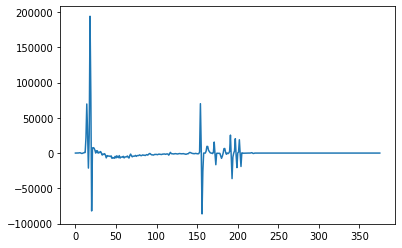

In [51]:
plt.plot(diff)

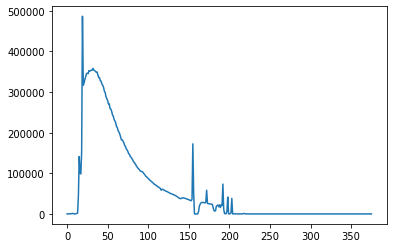

In [30]:
plt.plot(cnt)

In [21]:
v0.grid_index

array([ 38, 244, 397])

In [16]:
files = glob(str(data_dir / '*.e57'))

TypeError: unsupported operand type(s) for /: 'str' and 'str'

In [36]:
Path(files[0]).stem

'Jb-448 Exports_FARO_LS03550_088'